# Notebook 01: Problem Definition, Data Acquisition & Initial Exploratory Analysis
**Project:** Mineral Prospects — Geospatial Machine Learning for Mineral Prospectivity Mapping in Zambia  
**Target Mineral System:** Central African Copperbelt — Sediment-Hosted Stratiform Cu-Co (SSC)  

> **Scientific Integrity & Portfolio Disclaimer:**  
> This notebook is part of an open-science Data Science portfolio project. It integrates publicly documented geological principles of the Zambian Copperbelt with clearly flagged synthetic/benchmark layers where high-resolution proprietary surveys are restricted. **Predicted probabilities represent statistical compatibility with ore-forming spatial proxies—not confirmed mineral resources or discoveries.**

## 1. Environment Setup & Configuration Loading
We load project parameters from `configs/config.yaml` and import reusable functions from `src.data` to keep notebooks modular and testable.

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Add repository root to Python path
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.acquisition import (
    generate_zambia_prospectivity_benchmark,
    load_config,
)
from src.data.cleaning import (
    summarize_geochemical_outliers,
    validate_and_standardize_geodata,
)

sns.set_theme(style="whitegrid", palette="deep")
config = load_config(PROJECT_ROOT / "configs" / "config.yaml")
print(f"Loaded configuration for: {config['project']['title']}")
print(f"Target Projected CRS: {config['crs']['projected_crs']}")

Loaded configuration for: Mineral Prospects: Geospatial Machine Learning for Mineral Prospectivity Mapping in Zambia
Target Projected CRS: EPSG:32735


## 2. Data Acquisition & Benchmark Generation
Here we generate (or ingest, when external shapefiles/GeoTIFFs are placed in `data/external/`) the multi-disciplinary dataset covering the Zambian Copperbelt and North-Western Domes region (`EPSG:32735`, UTM Zone 35S).

In [2]:
raw_gdf, faults_gdf = generate_zambia_prospectivity_benchmark(config)

# Persist to data/processed for downstream notebooks
processed_dir = PROJECT_ROOT / config["data_paths"]["processed_dir"]
processed_dir.mkdir(parents=True, exist_ok=True)
raw_gdf.to_file(processed_dir / "zambia_cu_co_samples.gpkg", driver="GPKG")
faults_gdf.to_file(processed_dir / "zambia_fault_lineaments.gpkg", driver="GPKG")

print(f"Samples shape: {raw_gdf.shape} | Fault segments: {len(faults_gdf)}")
raw_gdf.head()

Samples shape: (2500, 17) | Fault segments: 18


,sample_id,geometry,dist_to_fault_m,lithology,dist_to_redox_contact_m,mag_anomaly_nt,bouguer_gravity_mgal,radiometric_k_th_ratio,elevation_m,slope_deg,cu_ppm,co_ppm,mineral_occurrence,longitude,latitude,is_synthetic,data_source
0,ZMB_0000,POINT (656457.885 8561770.788),6033.105568,Lower_Roan_Ore_Shale_Arkose,396.339372,24.029452,-145.394802,0.270439,1392.416573,4.179086,56.98,7.02,0,28.442684,-13.005879,True,SYNTHETIC_ZAMBIA_COPPERBELT_BENCHMARK
1,ZMB_0001,POINT (322937.751 8674184.468),7410.035924,Mwashia_Carbonaceous_Shale,16306.330987,16.006748,-120.207817,0.216744,1355.421782,1.246511,158.48,13.81,1,25.373742,-11.988604,True,SYNTHETIC_ZAMBIA_COPPERBELT_BENCHMARK
2,ZMB_0002,POINT (707516.171 8713874.335),76783.250589,Kundelungu_Glaciogenic_Siltstone,83864.019625,-34.712398,-121.728865,0.145362,1274.542860,1.245092,15.68,11.64,0,28.903389,-11.628105,True,SYNTHETIC_ZAMBIA_COPPERBELT_BENCHMARK
3,ZMB_0003,POINT (624811.143 8633601.787),3714.703973,Upper_Roan_Dolomite,8782.580163,-7.295773,-142.219665,0.240711,1321.461487,3.427978,20.35,11.60,0,28.148005,-12.357905,True,SYNTHETIC_ZAMBIA_COPPERBELT_BENCHMARK
4,ZMB_0004,POINT (337744.305 8634847.042),15098.289337,Lower_Roan_Ore_Shale_Arkose,3975.709850,14.081091,-139.322257,0.226100,1361.031195,1.131772,32.10,14.01,0,25.507718,-12.344978,True,SYNTHETIC_ZAMBIA_COPPERBELT_BENCHMARK


## 3. Geospatial Data Quality & CRS Validation Checks
Every coordinate is verified against Zambia's geographic extent, checked for valid `Shapely` geometry, deduplicated, and verified to be in metric `EPSG:32735` so distance calculations (`dist_to_fault_m`) are distortion-free.

In [3]:
clean_gdf, qa_report = validate_and_standardize_geodata(
    raw_gdf, target_crs=config["crs"]["projected_crs"]
)
pd.Series(qa_report, name="QA_Check_Value").to_frame()

,QA_Check_Value
initial_records,2500
null_geometries_removed,0
invalid_geometries_removed,0
out_of_zambia_bounds_removed,0
duplicate_ids_removed,0
duplicate_coordinates_removed,0
final_valid_records,2500
target_crs,EPSG:32735
is_projected_metric,True


## 4. Exploratory Geochemical & Lithological Analysis
In exploration geochemistry, trace element concentrations ($\text{Cu}$, $\text{Co}$) typically follow a right-skewed or log-normal distribution ($\log_{10}(\text{ppm})$). Upper-tail values are **pathfinder anomalies** rather than noise to be discarded.

In [4]:
geochem_summary = summarize_geochemical_outliers(clean_gdf, ["cu_ppm", "co_ppm"])
display(geochem_summary)

# Lithological breakdown of mineral occurrences
lith_summary = (
    clean_gdf.groupby("lithology")
    .agg(
        total_samples=("sample_id", "count"),
        occurrences=("mineral_occurrence", "sum"),
        occurrence_rate_pct=("mineral_occurrence", lambda s: round(100.0 * s.mean(), 2)),
        median_cu_ppm=("cu_ppm", "median"),
        median_dist_fault_m=("dist_to_fault_m", "median"),
    )
    .sort_values("occurrence_rate_pct", ascending=False)
)
display(lith_summary)

,element,count,missing_pct,median_ppm,iqr_ppm,max_ppm,log10_mad_threshold_ppm,anomalous_samples_count,anomalous_samples_pct
0,cu_ppm,2500,0.0,29.18,22.11,417.55,87.44,80,3.20
1,co_ppm,2500,0.0,8.02,5.38,46.34,21.50,73,2.92


,total_samples,occurrences,occurrence_rate_pct,median_cu_ppm,median_dist_fault_m
lithology,,,,,
Lower_Roan_Ore_Shale_Arkose,298,47,15.77,51.02,8865.854494
Mwashia_Carbonaceous_Shale,296,30,10.14,38.06,19895.472361
Kundelungu_Glaciogenic_Siltstone,1418,104,7.33,26.84,39388.934813
Basement_Granite_Gneiss,227,12,5.29,23.38,5457.035241
Upper_Roan_Dolomite,261,13,4.98,24.92,14599.992757


## 5. Multi-Panel Geospatial & Statistical Overview
We inspect:
1. **Spatial distribution** of structural lineaments (`faults_gdf`) and mineral occurrences in UTM Zone 35S.
2. **Log-space geochemical distributions** comparing mineralized (`1`) vs. background (`0`) locations.
3. **Structural proximity decay** showing how empirical occurrence probability varies with distance to faults.

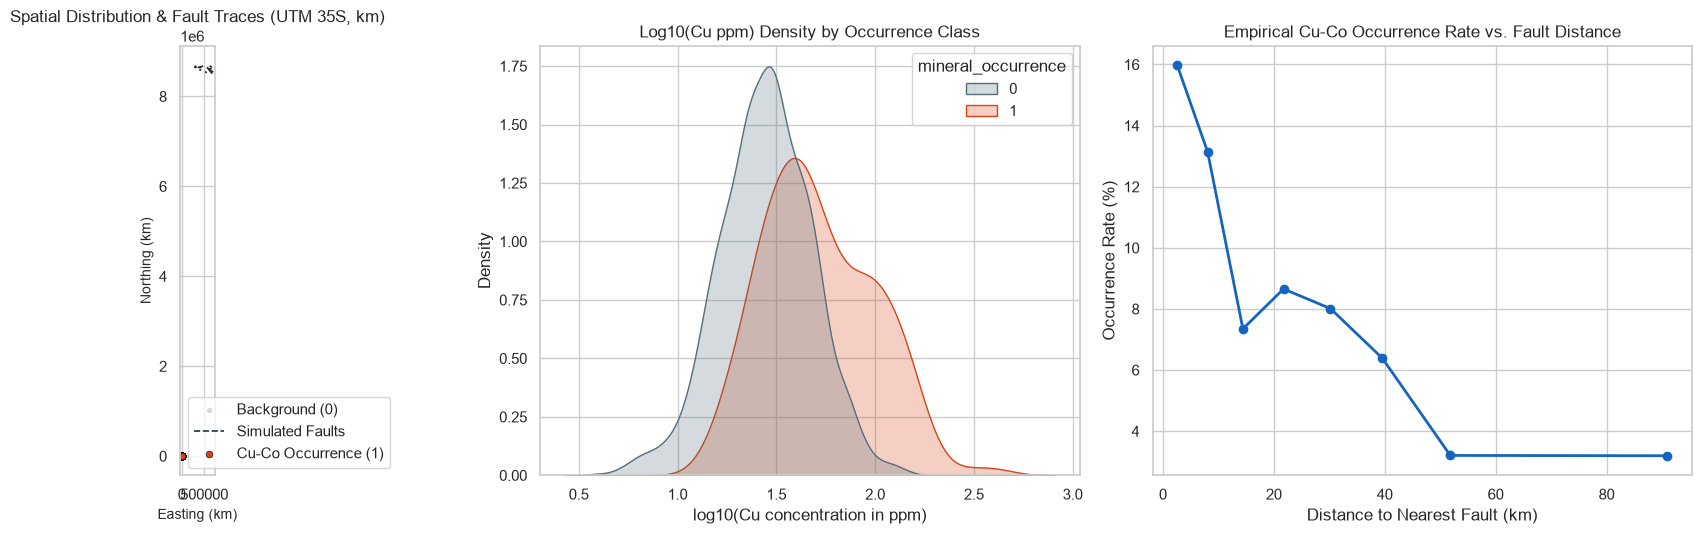

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel 1: Spatial map in UTM 35S
ax0 = axes[0]
bg = clean_gdf[clean_gdf["mineral_occurrence"] == 0]
pos = clean_gdf[clean_gdf["mineral_occurrence"] == 1]
ax0.scatter(bg.geometry.x / 1000, bg.geometry.y / 1000, c="#b0bec5", s=8, alpha=0.45, label="Background (0)")
faults_gdf.plot(ax=ax0, color="#263238", linewidth=1.2, linestyle="--", label="Simulated Faults")
ax0.scatter(pos.geometry.x / 1000, pos.geometry.y / 1000, c="#d84315", s=24, edgecolor="black", linewidth=0.4, label="Cu-Co Occurrence (1)")
ax0.set_title("Spatial Distribution & Fault Traces (UTM 35S, km)")
ax0.set_xlabel("Easting (km)")
ax0.set_ylabel("Northing (km)")
ax0.legend(loc="lower left", frameon=True)

# Panel 2: Log10(Cu ppm) distribution by target class
ax1 = axes[1]
sns.kdeplot(
    data=clean_gdf,
    x=np.log10(clean_gdf["cu_ppm"]),
    hue="mineral_occurrence",
    common_norm=False,
    fill=True,
    palette={0: "#546e7a", 1: "#d84315"},
    ax=ax1,
)
ax1.set_title("Log10(Cu ppm) Density by Occurrence Class")
ax1.set_xlabel("log10(Cu concentration in ppm)")

# Panel 3: Distance to fault vs occurrence rate
ax2 = axes[2]
clean_gdf["fault_dist_bin_km"] = pd.qcut(clean_gdf["dist_to_fault_m"] / 1000.0, q=8)
bin_rates = clean_gdf.groupby("fault_dist_bin_km", observed=False)["mineral_occurrence"].mean() * 100.0
bin_centers = [interval.mid for interval in bin_rates.index]
ax2.plot(bin_centers, bin_rates.values, marker="o", color="#1565c0", linewidth=2)
ax2.set_title("Empirical Cu-Co Occurrence Rate vs. Fault Distance")
ax2.set_xlabel("Distance to Nearest Fault (km)")
ax2.set_ylabel("Occurrence Rate (%)")

plt.tight_layout()
plt.show()